# Simple and multiple regression: energy, market and oil

This notebook analyses monthly US energy-sector excess returns for **2011–2025**.
A market-only regression is followed by a regression including changes in the
Brent oil price. The focus is on coefficient interpretation, uncertainty and
comparison of the two specifications on the same sample.

## Environment setup

**Colab:** upload the complete `Notebooks` folder to **My Drive**, keeping the
subfolders and CSV files. Run the cell below and authorise Drive access.
**Local Jupyter:** keep the same folder structure and run the cell below.
If the folder is elsewhere, set `NOTEBOOKS_ROOT` to its full path.

In [1]:
from pathlib import Path

# Usually leave this as None. If needed, enter the path to the folder
# containing all tutorial subfolders (Google Drive or the Colab runtime).
NOTEBOOKS_ROOT = None
TUTORIAL = "OLS"

try:
    from google.colab import drive
except ImportError:
    IN_COLAB = False
else:
    IN_COLAB = True

if IN_COLAB:
    notebooks_root = Path(NOTEBOOKS_ROOT or "/content/drive/MyDrive/Notebooks")
    if notebooks_root.is_relative_to("/content/drive"):
        drive.mount("/content/drive")
else:
    if NOTEBOOKS_ROOT is not None:
        notebooks_root = Path(NOTEBOOKS_ROOT).expanduser().resolve()
    else:
        # Work from the tutorial folder, Notebooks, or the course folder.
        here = Path.cwd().resolve()
        candidates = [here, *here.parents]
        candidates += [parent / "Notebooks" for parent in [here, *here.parents]]
        notebooks_root = next(
            (root for root in candidates if (root / TUTORIAL).is_dir()), here
        )

DATA_DIR = notebooks_root / TUTORIAL
if not DATA_DIR.is_dir():
    raise FileNotFoundError(
        f"Tutorial folder not found: {DATA_DIR}. "
        "Upload the complete Notebooks folder to My Drive, or set "
        "NOTEBOOKS_ROOT to the folder containing the tutorial subfolders."
    )
print(f"Data folder found: {DATA_DIR.name}")

Data folder found: OLS


## Libraries

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import statsmodels.api as sm
from IPython.display import display

## Data and units

- **Energy:** total returns on the value-weighted `Enrgy` portfolio in the
  [Kenneth French 12 industry portfolios](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/det_12_ind_port.html).
  It contains US energy-sector stocks, weighted by market capitalisation; it is
  a sector portfolio, rather than an individual stock.
- **Market:** the value-weighted return on eligible US stocks listed on NYSE,
  AMEX and NASDAQ in CRSP, **minus the monthly risk-free return**. This broad
  equity-market proxy is the `Mkt-RF` series in the
  [Kenneth French factor data](https://mba.tuck.dartmouth.edu/pages/faculty/ken.french/Data_Library/f-f_factors.html),
  not the S&P 500. **RF** is the matched monthly risk-free return from those data.
- **Brent:** the last available [EIA/FRED spot price](https://fred.stlouisfed.org/series/DCOILBRENTEU)
  in each month. Its percentage change is an explanatory variable, not a futures return.

Equity returns and RF are supplied as decimals. We subtract the matched monthly RF
from the energy total return. The market series is already an excess return,
so RF must **not** be subtracted from it again.

All regression variables below are in **percent**: a value of 1 means a 1% return.
A one-unit increase is therefore **one percentage point**, not a 1% increase relative
to the variable's previous value. RF is a monthly return, not an annualised yield.

December 2010 provides the base price for the first Brent change. It is excluded
from estimation. Month-end labels identify the month; the CSV also records the
date of the Brent price actually used.

In [3]:
data = pd.read_csv(DATA_DIR / "monthly_energy_market_data.csv", parse_dates=["date"])
data = data.set_index("date").sort_index()

returns = pd.DataFrame({
    "Energy": 100 * (data["Energy"] - data["RF"]),
    "Market": 100 * data["Market_excess"],
    "Brent": 100 * data["Brent_spot"].pct_change(fill_method=None),
}).loc["2011-01-01":"2025-12-31"]

if returns.isna().any().any():
    raise ValueError("Missing observations: check the data before comparing the models.")
print(f"Estimation sample: {returns.index[0]:%Y-%m} to {returns.index[-1]:%Y-%m}; {len(returns)} months")
display(returns.head().round(3))

Estimation sample: 2011-01 to 2025-12; 180 months


,Energy,Market,Brent
date,,,
2011-01-31,6.92,1.98,6.157
2011-02-28,7.62,3.48,13.438
2011-03-31,2.10,0.45,4.160
2011-04-30,1.58,2.90,8.252
2011-05-31,-4.51,-1.27,-7.433


## Economic context

Energy stocks are exposed to broad equity-market movements and to developments
in the oil market. Oil-price movements and market returns can themselves be
related. Neither variable determines every monthly energy return: firm-specific
news and other economic developments also contribute to the variation.

## 1. Simple regression: the market model

The CAPM-style excess-return regression is

$$r^e_{E,t}=\alpha+\beta_M r^e_{M,t}+u_t.$$

The intercept is the fitted energy excess return when the market excess return is
zero. The slope measures the fitted change in energy excess return associated with
a one-percentage-point increase in market excess return.

The intercept is often called **alpha**, and the market slope **beta**. CAPM
reasoning applies to portfolios as well as individual stocks. Here the dependent
variable is the energy-sector portfolio and the regressor is a broad US equity
market proxy. This regression illustrates the market relationship; it does not
by itself validate the CAPM. The CAPM pricing restriction would imply zero alpha
with an appropriate market portfolio and the required model assumptions.

OLS estimates the coefficients. The output uses **HAC standard errors** to allow
for heteroskedasticity and short-run serial dependence. This changes the reported
uncertainty, not the OLS coefficients or fitted line. The same settings are used
for both models; their role is revisited at the end of the notebook.

In [4]:
y = returns["Energy"]
# Newey–West HAC: Bartlett weights, three monthly lags and a sample-size correction.
# The t reference used for robust inference is an approximation, not an exact test.
HAC_OPTIONS = {"maxlags": 3, "kernel": "bartlett", "use_correction": True}

X_simple = sm.add_constant(returns[["Market"]])
simple = sm.OLS(y, X_simple, missing="raise").fit(
    cov_type="HAC", cov_kwds=HAC_OPTIONS, use_t=True
)
print(simple.summary())

                            OLS Regression Results                            
Dep. Variable:                 Energy   R-squared:                       0.401
Model:                            OLS   Adj. R-squared:                  0.398
Method:                 Least Squares   F-statistic:                     35.97
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           1.09e-08
Time:                        03:50:07   Log-Likelihood:                -577.72
No. Observations:                 180   AIC:                             1159.
Df Residuals:                     178   BIC:                             1166.
Df Model:                           1                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.6295      0.576     -1.093      0.2

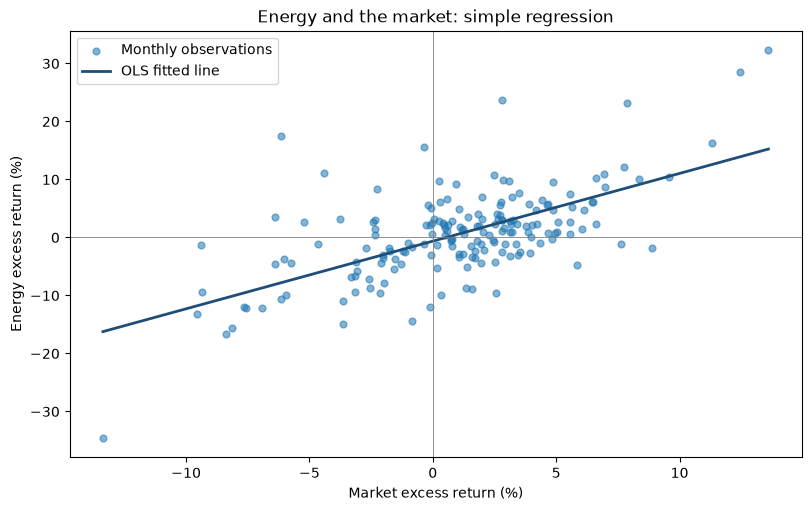

In [5]:
fig, ax = plt.subplots(figsize=(8, 5), constrained_layout=True)
ax.scatter(returns["Market"], y, s=24, alpha=0.55, label="Monthly observations")
market_grid = np.linspace(returns["Market"].min(), returns["Market"].max(), 100)
ax.plot(market_grid, simple.params["const"] + simple.params["Market"] * market_grid,
        color="#1F4E79", lw=2, label="OLS fitted line")
ax.axhline(0, color="grey", lw=0.6)
ax.axvline(0, color="grey", lw=0.6)
ax.set(xlabel="Market excess return (%)", ylabel="Energy excess return (%)",
       title="Energy and the market: simple regression")
ax.legend()
plt.show()

## Reading the regression output

| Output | Interpretation |
|---|---|
| `coef` | Estimated intercept or slope; interpret its sign, size and units. |
| `std err` | Estimated sampling uncertainty of the coefficient. It is not the volatility of returns or the standard deviation of the residuals. |
| `t` | For the displayed zero-coefficient test, the estimate divided by its standard error. |
| `P>|t|` | Two-sided p-value for $H_0:\theta=0$ against $H_1:\theta\ne0$, separately for each coefficient. |
| `[0.025, 0.975]` | Endpoints of the 95% confidence interval for the coefficient. |
| `R-squared` | Fraction of the sample variation in the dependent variable explained by the fitted regression with an intercept. |

Under $H_0$ and the test assumptions, the **p-value** is the probability of a test
statistic at least as extreme as the observed one, in either direction. It is not
the probability that $H_0$ is true, and does not measure the economic size of an effect.
A displayed `0.000` is rounding, not an exactly zero probability.

At 5%, reject the zero-coefficient null when the p-value is below 0.05. Non-rejection
does not establish that the coefficient is zero. A **Type I error** is rejecting a
true null; the significance level concerns repeated use of the test under that null.

A 95% confidence-interval procedure covers the true coefficient in 95% of repeated
samples under its assumptions. Inclusion of zero corresponds to non-rejection by
the matching two-sided 5% test. Compare the width of the interval with the coefficient's size.

These are **HAC standard errors and approximate tests**. Their validity requires
appropriate exogeneity and regularity assumptions; robust standard errors do not
remove omitted-variable bias or establish causality. Heteroskedasticity and serial
correlation are examined in more detail in the later inference tutorial.

The reported market-beta p-value tests **beta = 0**, not beta = 1. A coefficient
can differ significantly from zero without differing significantly from one.
The scatter around the fitted line represents variation not explained by the market.

## 2. Multiple regression: adding Brent

$$r^e_{E,t}=\alpha+\beta_M r^e_{M,t}+\beta_O\Delta p^{Brent}_t+u_t.$$

$\Delta p^{Brent}_t$ is the monthly percentage change in the spot price.
The market coefficient now describes the association **holding Brent changes
constant**; the Brent coefficient holds market excess return constant.
The intercept corresponds to both explanatory variables being zero.

This is an extended return regression with two explanatory variables, rather
than the one-factor CAPM specification. Brent is a contemporaneous price change;
its coefficient describes a partial association, not an identified causal effect
or a directly tradable risk premium.

In [6]:
X_multiple = sm.add_constant(returns[["Market", "Brent"]])
multiple = sm.OLS(y, X_multiple, missing="raise").fit(
    cov_type="HAC", cov_kwds=HAC_OPTIONS, use_t=True
)
print(multiple.summary())

                            OLS Regression Results                            
Dep. Variable:                 Energy   R-squared:                       0.531
Model:                            OLS   Adj. R-squared:                  0.525
Method:                 Least Squares   F-statistic:                     50.03
Date:                Sun, 11 Oct 2026   Prob (F-statistic):           6.01e-18
Time:                        03:50:07   Log-Likelihood:                -555.78
No. Observations:                 180   AIC:                             1118.
Df Residuals:                     177   BIC:                             1127.
Df Model:                           2                                         
Covariance Type:                  HAC                                         
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const         -0.4757      0.486     -0.979      0.3

The Brent slope converts a change in the oil-price regressor into a fitted change
in energy excess return, **in percentage points**, with the market held constant.
A ten-percentage-point increase contributes ten times the estimated Brent slope.
Its standard error measures uncertainty about that slope, rather than the
volatility of Brent or energy returns. The displayed p-value tests
$H_0:\beta_O=0$ against $H_1:\beta_O\ne0$.

### The fitted regression plane

With two regressors, the fitted relationship is a **plane in three dimensions**.
Market and Brent form the two horizontal axes; energy excess return is the vertical
axis. The plane shows fitted values and the points show observed monthly returns.
Its two slopes correspond to changing one regressor while holding the other fixed.
The surface is restricted to the convex hull of the observed regressor pairs;
some combinations inside it can still be sparsely represented in the sample.

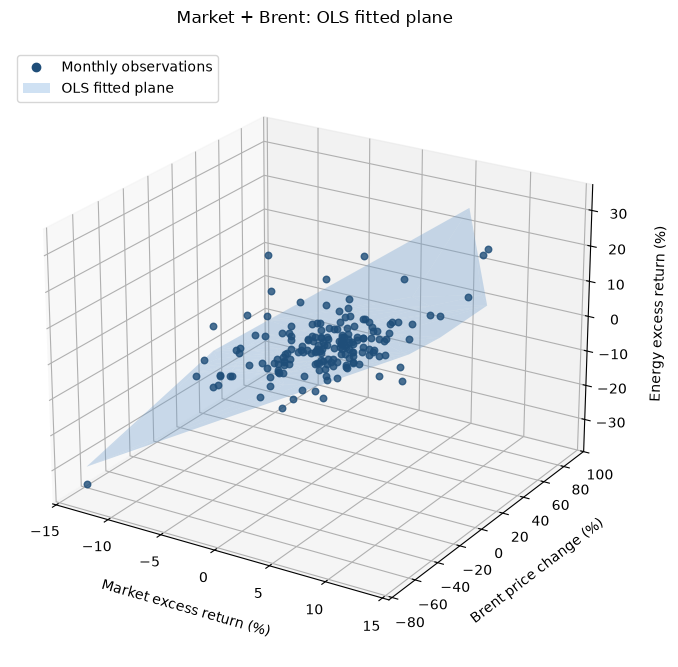

In [7]:
from matplotlib.tri import Triangulation
from matplotlib.patches import Patch
from matplotlib.lines import Line2D

fig = plt.figure(figsize=(10, 7))
ax = fig.add_subplot(111, projection="3d")
market = returns["Market"].to_numpy()
brent = returns["Brent"].to_numpy()
triangles = Triangulation(market, brent)
ax.plot_trisurf(triangles, multiple.fittedvalues.to_numpy(),
                color="#77AADD", alpha=0.35, linewidth=0)
ax.scatter(market, brent, y.to_numpy(), color="#1F4E79", s=22,
           alpha=0.8, depthshade=False)
ax.set_xlabel("Market excess return (%)", labelpad=10)
ax.set_ylabel("Brent price change (%)", labelpad=10)
ax.set_zlabel("Energy excess return (%)", labelpad=10)
ax.set_title("Market + Brent: OLS fitted plane", pad=18)
ax.view_init(elev=23, azim=-58)
ax.legend(handles=[Line2D([], [], marker="o", linestyle="", color="#1F4E79",
                         label="Monthly observations"),
                   Patch(facecolor="#77AADD", alpha=0.35, label="OLS fitted plane")],
          loc="upper left")
fig.subplots_adjust(left=0.02, right=0.88, bottom=0.05, top=0.92)
plt.show()

## 3. Comparing the models

Both models use the same months and dependent variable. The table compares
coefficients, their HAC standard errors and model fit. Residual standard deviation
is in percentage points and measures unexplained return variation.

The two-dimensional plots compare **observed and fitted energy returns**.
For the multiple model, each fitted value uses both Market and Brent. These plots
summarise fit; the three-dimensional plot above shows the regression geometry.
Points on the 45-degree line have an observed return equal to the fitted return.

In [8]:
models = {"Market only": simple, "Market + Brent": multiple}
comparison = pd.DataFrame({
    name: {"Observations": int(model.nobs),
           "Alpha (% per month)": model.params["const"],
           "Market beta": model.params["Market"],
           "SE: market beta": model.bse["Market"],
           "R-squared": model.rsquared,
           "Adjusted R-squared": model.rsquared_adj,
           "Residual SD (pp)": np.sqrt(model.mse_resid)}
    for name, model in models.items()
})
display(comparison.round(4))
print(f"Market–Brent sample correlation: {returns['Market'].corr(returns['Brent']):.3f}")

,Market only,Market + Brent
Observations,180.0000,180.0000
Alpha (% per month),-0.6295,-0.4757
Market beta,1.1672,0.8825
SE: market beta,0.1946,0.1787
R-squared,0.4010,0.5306
Adjusted R-squared,0.3977,0.5253
Residual SD (pp),6.0268,5.3503


Market–Brent sample correlation: 0.394


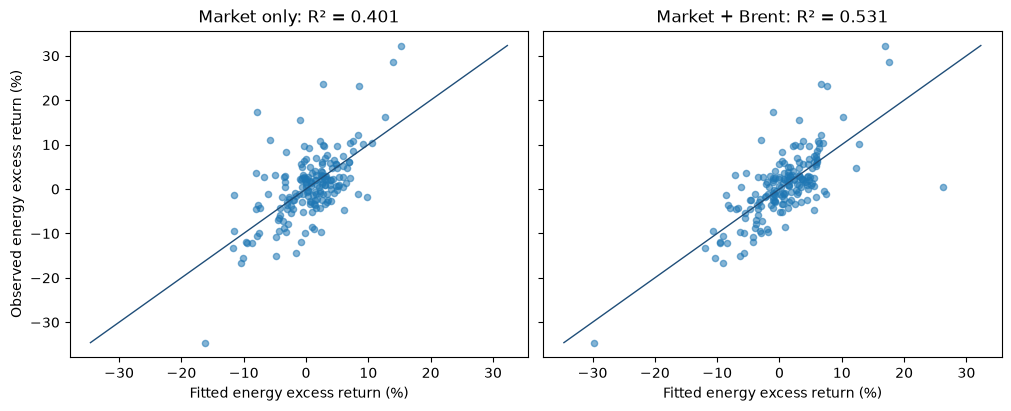

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=True,
                         constrained_layout=True)
limits = [min(y.min(), *(m.fittedvalues.min() for m in models.values())),
          max(y.max(), *(m.fittedvalues.max() for m in models.values()))]
for ax, (name, model) in zip(axes, models.items()):
    ax.scatter(model.fittedvalues, y, s=20, alpha=0.55)
    ax.plot(limits, limits, color="#1F4E79", lw=1)
    ax.set(title=f"{name}: R² = {model.rsquared:.3f}",
           xlabel="Fitted energy excess return (%)")
axes[0].set_ylabel("Observed energy excess return (%)")
plt.show()

Adding a regressor cannot lower ordinary in-sample $R^2$ on the same sample.
Adjusted $R^2$ penalises additional regressors and need not increase. Neither
statistic establishes causality or guarantees good forecasts.

The difference in market beta provides a link to **omitted variable bias**:
Brent's association with energy returns and its correlation with the market
help explain why the market slope changes. A changed coefficient alone does not
establish that either model identifies a causal parameter. Multiple-regression
coefficients describe partial associations unless further identifying assumptions
are justified.

## 4. Standard errors: a check for this dataset

Conventional OLS standard errors assume homoskedastic, serially uncorrelated errors.
**HC1** allows heteroskedasticity; **HAC** also allows short-run serial dependence.
All three methods below use exactly the same OLS coefficient estimates.
Their standard errors, p-values and confidence intervals can differ substantially.
See the [statsmodels documentation](https://www.statsmodels.org/stable/generated/statsmodels.regression.linear_model.RegressionResults.get_robustcov_results.html).

For these data, residual checks show clear heteroskedasticity in the multiple model.
Checks at one, three and six monthly lags do not reject absence of residual serial
correlation at 5%; non-rejection is not evidence that serial correlation is impossible.
Serial dependence in squared residuals can also coexist with weak correlation in
the residuals themselves. Monthly sampling does not ensure independent errors.

The main results therefore use HAC with Bartlett weights and **three monthly lags**,
an illustrative bandwidth covering one quarter. This is not a claim that three lags
capture all possible dependence. The table includes six lags as a sensitivity check.
Robust inference is approximate and still relies on a suitable specification and
exogeneity. The construction of these standard errors and the residual tests are
reserved for the later inference tutorial.

In [10]:
se_rows = []
for name, model in models.items():
    conventional = model.model.fit()
    variants = {
        "Conventional": conventional,
        "HC1": conventional.get_robustcov_results(cov_type="HC1", use_t=True),
        "HAC (3 lags)": model,
        "HAC (6 lags)": conventional.get_robustcov_results(
            cov_type="HAC", maxlags=6, kernel="bartlett",
            use_correction=True, use_t=True
        ),
    }
    for method, result in variants.items():
        for i, term in enumerate(model.model.exog_names):
            se_rows.append({"Model": name, "Term": term, "SE method": method,
                            "Coefficient": np.asarray(result.params)[i],
                            "Standard error": np.asarray(result.bse)[i],
                            "p-value (H0: coefficient = 0)": np.asarray(result.pvalues)[i]})
se_comparison = pd.DataFrame(se_rows).set_index(["Model", "Term", "SE method"])
with pd.option_context("display.float_format", lambda value: f"{value:.4g}"):
    display(se_comparison)

Coefficient  Standard error  \
Model          Term   SE method                                   
Market only    const  Conventional      -0.6295          0.4632   
               Market Conventional        1.167          0.1069   
               const  HC1               -0.6295          0.5013   
               Market HC1                 1.167          0.1635   
               const  HAC (3 lags)      -0.6295          0.5761   
               Market HAC (3 lags)        1.167          0.1946   
               const  HAC (6 lags)      -0.6295          0.6421   
               Market HAC (6 lags)        1.167          0.1948   
Market + Brent const  Conventional      -0.4757          0.4118   
               Market Conventional       0.8825          0.1033   
               Brent  Conventional       0.2455         0.03513   
               const  HC1               -0.4757          0.4283   
               Market HC1                0.8825          0.1539   
               Brent  HC1                0.2455             0.1   
               const  HAC (3 lags)      -0.4757          0.4858   
               Market HAC (3 lags)       0.8825          0.1787   
               Brent  HAC (3 lags)       0.2455         0.09755   
               const  HAC (6 lags)      -0.4757          0.5518   
               Market HAC (6 lags)       0.8825          0.1854   
               Brent  HAC (6 lags)       0.2455         0.09276   

                                    p-value (H0: coefficient = 0)  
Model          Term   SE method                                    
Market only    const  Conventional                         0.1759  
               Market Conventional                      1.446e-21  
               const  HC1                                  0.2109  
               Market HC1                               2.313e-11  
               const  HAC (3 lags)                          0.276  
               Market HAC (3 lags)                      1.091e-08  
               const  HAC (6 lags)                         0.3283  
               Market HAC (6 lags)                      1.117e-08  
Market + Brent const  Conventional                         0.2496  
               Market Conventional                      5.816e-15  
               Brent  Conventional                      5.397e-11  
               const  HC1                                  0.2682  
               Market HC1                               4.125e-08  
               Brent  HC1                                 0.01507  
               const  HAC (3 lags)                         0.3288  
               Market HAC (3 lags)                      1.801e-06  
               Brent  HAC (3 lags)                        0.01273  
               const  HAC (6 lags)                         0.3899  
               Market HAC (6 lags)                      4.006e-06  
               Brent  HAC (6 lags)                        0.00885